<a href="https://colab.research.google.com/github/Higor-V/Higor-V-NaiveJus-ML-Bruno-Higor-Yuri/blob/main/NaiveJus_2_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install scikit-learn pypdf python-docx

import io
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Bibliotecas prontas.")

Bibliotecas prontas.


In [2]:
dados = [
    {"texto": 'O requerente solicita o fornecimento do medicamento prescrito pelo médico.', "categoria": 'medicamento'},
    {"texto": 'Pedido judicial para disponibilização de fármaco de uso contínuo.', "categoria": 'medicamento'},
    {"texto": 'A parte autora requer medicamento de alto custo não fornecido regularmente.', "categoria": 'medicamento'},
    {"texto": 'Solicita-se a entrega do remédio indicado na receita médica.', "categoria": 'medicamento'},
    {"texto": 'O paciente pede o fornecimento de comprimidos para controle da doença.', "categoria": 'medicamento'},
    {"texto": 'A ação requer acesso a medicamento registrado na Anvisa.', "categoria": 'medicamento'},
    {"texto": 'A demanda trata da falta de medicamento na farmácia pública.', "categoria": 'medicamento'},
    {"texto": 'O autor solicita insulina e outros medicamentos para uso diário.', "categoria": 'medicamento'},
    {"texto": 'Pedido de fornecimento de medicamento oncológico conforme prescrição.', "categoria": 'medicamento'},
    {"texto": 'A petição pede um fármaco específico para continuidade da terapia.', "categoria": 'medicamento'},
    {"texto": 'Requer-se que o município disponibilize o remédio receitado.', "categoria": 'medicamento'},
    {"texto": 'O processo discute a dispensação de medicamento pelo SUS.', "categoria": 'medicamento'},
    {"texto": 'A família solicita a compra de medicamento que não está disponível.', "categoria": 'medicamento'},
    {"texto": 'O pedido busca garantir o acesso ao princípio ativo indicado pelo especialista.', "categoria": 'medicamento'},
    {"texto": 'A parte requer a renovação do fornecimento de medicamento de uso prolongado.', "categoria": 'medicamento'},
    {"texto": 'Solicita-se medicamento imunobiológico para tratamento de doença crônica.', "categoria": 'medicamento'},
    {"texto": 'O paciente pede o fornecimento de cápsulas prescritas em relatório clínico.', "categoria": 'medicamento'},
    {"texto": 'A demanda judicial busca obter o fármaco prescrito e indisponível na rede pública.', "categoria": 'medicamento'},
    {"texto": 'A petição solicita a dispensação de antibiótico conforme receita.', "categoria": 'medicamento'},
    {"texto": 'O requerente pede que o Estado forneça os medicamentos descritos na prescrição.', "categoria": 'medicamento'},
    {"texto": 'O requerente solicita a realização de cirurgia ortopédica.', "categoria": 'cirurgia'},
    {"texto": 'Pedido judicial para agendamento de procedimento cirúrgico urgente.', "categoria": 'cirurgia'},
    {"texto": 'A parte autora requer cirurgia para correção de hérnia.', "categoria": 'cirurgia'},
    {"texto": 'O paciente aguarda intervenção cirúrgica pelo sistema público.', "categoria": 'cirurgia'},
    {"texto": 'A demanda trata da realização de cirurgia cardíaca.', "categoria": 'cirurgia'},
    {"texto": 'Solicita-se autorização para procedimento cirúrgico indicado pelo especialista.', "categoria": 'cirurgia'},
    {"texto": 'O processo pede cirurgia de catarata na rede pública.', "categoria": 'cirurgia'},
    {"texto": 'O autor busca reduzir a fila para uma operação de coluna.', "categoria": 'cirurgia'},
    {"texto": 'A petição requer cirurgia bariátrica após avaliação médica.', "categoria": 'cirurgia'},
    {"texto": 'O paciente precisa de cirurgia para retirada de tumor.', "categoria": 'cirurgia'},
    {"texto": 'A família pede a realização de transplante conforme indicação clínica.', "categoria": 'cirurgia'},
    {"texto": 'O pedido é para uma intervenção cirúrgica reparadora.', "categoria": 'cirurgia'},
    {"texto": 'A ação solicita cirurgia vascular em hospital conveniado.', "categoria": 'cirurgia'},
    {"texto": 'O requerente pede operação para tratamento de lesão no joelho.', "categoria": 'cirurgia'},
    {"texto": 'A demanda busca autorização de cirurgia neurológica.', "categoria": 'cirurgia'},
    {"texto": 'O paciente aguarda procedimento cirúrgico eletivo há vários meses.', "categoria": 'cirurgia'},
    {"texto": 'Solicita-se cirurgia para correção de catarata bilateral.', "categoria": 'cirurgia'},
    {"texto": 'A petição pede que o ente público providencie a operação recomendada.', "categoria": 'cirurgia'},
    {"texto": 'O pedido judicial refere-se a cirurgia de prótese de quadril.', "categoria": 'cirurgia'},
    {"texto": 'O autor requer internação para realização de procedimento cirúrgico.', "categoria": 'cirurgia'},
    {"texto": 'O requerente solicita a realização de exame de ressonância magnética.', "categoria": 'exame'},
    {"texto": 'Pedido para agendamento de tomografia computadorizada.', "categoria": 'exame'},
    {"texto": 'A parte autora requer exame laboratorial específico.', "categoria": 'exame'},
    {"texto": 'O paciente aguarda ultrassonografia pela rede pública.', "categoria": 'exame'},
    {"texto": 'A demanda trata do acesso a exame de colonoscopia.', "categoria": 'exame'},
    {"texto": 'Solicita-se exame de sangue para investigação diagnóstica.', "categoria": 'exame'},
    {"texto": 'O processo pede uma mamografia que ainda não foi agendada.', "categoria": 'exame'},
    {"texto": 'O autor requer ecocardiograma solicitado pelo cardiologista.', "categoria": 'exame'},
    {"texto": 'A petição busca garantir o exame de biópsia.', "categoria": 'exame'},
    {"texto": 'O paciente precisa realizar uma endoscopia digestiva.', "categoria": 'exame'},
    {"texto": 'A família solicita exame de imagem para esclarecer o diagnóstico.', "categoria": 'exame'},
    {"texto": 'O pedido judicial trata da realização de eletroencefalograma.', "categoria": 'exame'},
    {"texto": 'O requerente pede teste genético para investigação clínica.', "categoria": 'exame'},
    {"texto": 'A demanda é sobre exame de densitometria óssea.', "categoria": 'exame'},
    {"texto": 'O paciente necessita de cintilografia indicada em relatório.', "categoria": 'exame'},
    {"texto": 'Solicita-se teste diagnóstico que não está disponível no município.', "categoria": 'exame'},
    {"texto": 'A petição requer exame de angiografia para avaliar os vasos.', "categoria": 'exame'},
    {"texto": 'O autor pede coleta e análise laboratorial de amostras.', "categoria": 'exame'},
    {"texto": 'O processo solicita exame de PET-CT para avaliação médica.', "categoria": 'exame'},
    {"texto": 'A ação busca agendamento de exame oftalmológico especializado.', "categoria": 'exame'},
    {"texto": 'O requerente solicita sessões de fisioterapia para reabilitação.', "categoria": 'tratamento'},
    {"texto": 'Pedido judicial para iniciar radioterapia conforme plano terapêutico.', "categoria": 'tratamento'},
    {"texto": 'A parte autora requer acompanhamento psicológico continuado.', "categoria": 'tratamento'},
    {"texto": 'O paciente necessita de tratamento fonoaudiológico.', "categoria": 'tratamento'},
    {"texto": 'A demanda trata de sessões de hemodiálise.', "categoria": 'tratamento'},
    {"texto": 'Solicita-se terapia ocupacional para recuperar a autonomia funcional.', "categoria": 'tratamento'},
    {"texto": 'O processo pede tratamento multidisciplinar para reabilitação.', "categoria": 'tratamento'},
    {"texto": 'O autor requer acesso a quimioterapia em serviço especializado.', "categoria": 'tratamento'},
    {"texto": 'A família solicita atendimento domiciliar de reabilitação.', "categoria": 'tratamento'},
    {"texto": 'O paciente aguarda tratamento especializado para sua condição.', "categoria": 'tratamento'},
    {"texto": 'A petição pede sessões de psicoterapia pela rede pública.', "categoria": 'tratamento'},
    {"texto": 'O requerente solicita tratamento odontológico especializado.', "categoria": 'tratamento'},
    {"texto": 'A demanda judicial envolve programa de reabilitação física.', "categoria": 'tratamento'},
    {"texto": 'O paciente necessita de terapia renal substitutiva continuada.', "categoria": 'tratamento'},
    {"texto": 'Solicita-se tratamento nutricional acompanhado por equipe profissional.', "categoria": 'tratamento'},
    {"texto": 'O pedido é para iniciar tratamento fisioterapêutico pós-operatório.', "categoria": 'tratamento'},
    {"texto": 'A parte autora requer acompanhamento terapêutico regular.', "categoria": 'tratamento'},
    {"texto": 'O processo solicita tratamento de radioterapia em hospital de referência.', "categoria": 'tratamento'},
    {"texto": 'O autor pede atendimento de terapia ocupacional na rede pública.', "categoria": 'tratamento'},
    {"texto": 'A demanda busca garantir tratamento reabilitador após acidente.', "categoria": 'tratamento'},

]


df = pd.DataFrame(dados)
print(f"Total de exemplos: {len(df)}")
display(df.groupby('categoria').size().rename('quantidade').to_frame())

Total de exemplos: 80


,quantidade
categoria,
cirurgia,20
exame,20
medicamento,20
tratamento,20


In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    df["texto"], df["categoria"], test_size=0.25, random_state=42, stratify=df["categoria"]
)

def criar_modelo():
    return Pipeline([
        ("vetorizador", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 8),
            strip_accents="unicode", sublinear_tf=True
        )),
        ("classificador", MultinomialNB())
    ])

modelo_avaliacao = criar_modelo()
modelo_avaliacao.fit(X_treino, y_treino)
predicoes = modelo_avaliacao.predict(X_teste)

print(f"Acurácia no conjunto de teste: {accuracy_score(y_teste, predicoes):.1%}")
print("\nRelatório por categoria:")
print(classification_report(y_teste, predicoes, zero_division=0))

# Modelo final: treinado com todos os exemplos sintéticos.
modelo = criar_modelo()
modelo.fit(df["texto"], df["categoria"])
print("Modelo final treinado e pronto para receber documentos.")

Acurácia no conjunto de teste: 85.0%

Relatório por categoria:
              precision    recall  f1-score   support

    cirurgia       0.71      1.00      0.83         5
       exame       1.00      0.60      0.75         5
 medicamento       0.83      1.00      0.91         5
  tratamento       1.00      0.80      0.89         5

    accuracy                           0.85        20
   macro avg       0.89      0.85      0.85        20
weighted avg       0.89      0.85      0.85        20

Modelo final treinado e pronto para receber documentos.


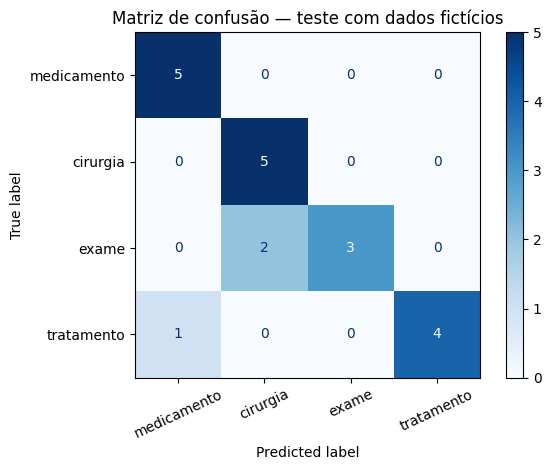

In [4]:
ordem = ["medicamento", "cirurgia", "exame", "tratamento"]
ConfusionMatrixDisplay.from_predictions(
    y_teste, predicoes, labels=ordem, display_labels=ordem,
    xticks_rotation=25, cmap="Blues"
)
plt.title("Matriz de confusão — teste com dados fictícios")
plt.tight_layout()
plt.show()

In [5]:
from pypdf import PdfReader
from docx import Document

def extrair_texto_pdf(conteudo_bytes):
    leitor = PdfReader(io.BytesIO(conteudo_bytes))
    partes = []
    for pagina in leitor.pages:
        partes.append(pagina.extract_text() or "")
    return "\n".join(partes).strip()


def extrair_texto_docx(conteudo_bytes):
    documento = Document(io.BytesIO(conteudo_bytes))
    partes = [p.text for p in documento.paragraphs if p.text.strip()]
    # Também considera conteúdo que esteja dentro de tabelas.
    for tabela in documento.tables:
        for linha in tabela.rows:
            partes.append(" | ".join(celula.text for celula in linha.cells))
    return "\n".join(partes).strip()


def extrair_texto_arquivo(nome_arquivo, conteudo_bytes):
    extensao = nome_arquivo.lower().rsplit(".", 1)[-1] if "." in nome_arquivo else ""
    if extensao == "pdf":
        texto = extrair_texto_pdf(conteudo_bytes)
    elif extensao == "docx":
        texto = extrair_texto_docx(conteudo_bytes)
    elif extensao == "txt":
        try:
            texto = conteudo_bytes.decode("utf-8-sig")
        except UnicodeDecodeError:
            texto = conteudo_bytes.decode("cp1252", errors="replace")
    else:
        raise ValueError("Formato não aceito. Envie um arquivo PDF, DOCX ou TXT.")

    if not texto.strip():
        raise ValueError(
            "Não foi possível extrair texto deste arquivo. Se for um PDF digitalizado como imagem, "
            "esta versão ainda não possui OCR."
        )
    return texto

In [6]:
def classificar_documento(texto):
    if not isinstance(texto, str) or not texto.strip():
        raise ValueError("O documento não contém texto para classificar.")

    categoria = modelo.predict([texto])[0]
    pontuacoes = modelo.predict_proba([texto])[0]
    classes = modelo.named_steps["classificador"].classes_
    maior_pontuacao = float(max(pontuacoes))

    print(f"Categoria sugerida: {categoria.upper()}")
    print(f"Pontuação estimada para a categoria sugerida: {maior_pontuacao:.1%}")
    print("\nPontuações estimadas por categoria:")
    for classe, valor in sorted(zip(classes, pontuacoes), key=lambda item: item[1], reverse=True):
        print(f"- {classe}: {valor:.1%}")

    if maior_pontuacao < 0.45:
        print("\nALERTA: classificação pouco definida. Encaminhe para revisão humana.")
    else:
        print("\nAtenção: revise a sugestão antes de utilizá-la. A pontuação não garante que a categoria esteja correta.")

    return categoria

In [7]:
from google.colab import files

arquivos_enviados = files.upload()

if not arquivos_enviados:
    print("Nenhum arquivo foi enviado.")
else:
    for nome, conteudo in arquivos_enviados.items():
        print("\n" + "=" * 70)
        print(f"DOCUMENTO: {nome}")
        print("=" * 70)
        try:
            texto_extraido = extrair_texto_arquivo(nome, conteudo)
            print(f"Caracteres extraídos: {len(texto_extraido)}")
            print("\nPrévia do texto extraído:")
            print(texto_extraido[:900] + ("..." if len(texto_extraido) > 900 else ""))
            print("\nRESULTADO DA CLASSIFICAÇÃO")
            classificar_documento(texto_extraido)
        except Exception as erro:
            print(f"Não foi possível processar este arquivo: {erro}")

Saving Documento_Medicamento.pdf to Documento_Medicamento.pdf

DOCUMENTO: Documento_Medicamento.pdf
Caracteres extraídos: 1425

Prévia do texto extraído:
DOCUMENTO FICTÍCIO — USO ACADÊMICO 
REQUERIMENTO JUDICIAL SIMULADO 
Pedido fictício de fornecimento de medicamento 
 
À AUTORIDADE JUDICIÁRIA COMPETENTE 
Parte requerente: Marcia Almeida 
Parte requerida: Ente público 
Assunto: Solicitação de fornecimento de medicamento 
1. Descrição do pedido 
A parte requerente, identificada neste exercício exclusivamente como Marcia Almeida, 
apresenta pedido para obtenção de medicamento de uso contínuo, denominado neste 
documento como “Medicamento Alfa”. 
Segundo a narrativa hipotética, existe prescrição médica indicando a necessidade de uso 
regular do fármaco. A parte informa que não conseguiu obter o remédio pela via administrativa 
e solicita o fornecimento periódico da quantidade indicada na receita. 
2. Fundamentação da solicitação 
O pedido apresentado neste exemplo tem como objeto específ